# Tomato Crop Disease Classification

This notebook trains and evaluates a ResNet18 image classifier for 10 tomato leaf classes from the PlantVillage dataset.

**Workflow:** dataset inspection → extraction → preprocessing → stratified split → transfer learning → evaluation → saving artifacts → single-image inference.

> **Environment:** Google Colab with GPU recommended. The dataset ZIP is expected at `MyDrive/Crop_Disease_Project/archive.zip`.

## 1. Google Drive and project paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import random
import zipfile
from collections import Counter
from io import BytesIO

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

project_path = "/content/drive/MyDrive/Crop_Disease_Project"
zip_path = os.path.join(project_path, "archive.zip")
dataset_path = "/content/tomato_dataset"
model_save_path = os.path.join(project_path, "models")
results_save_path = os.path.join(project_path, "results")

os.makedirs(model_save_path, exist_ok=True)
os.makedirs(results_save_path, exist_ok=True)

print("Project folder contents:", os.listdir(project_path))
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

Mounted at /content/drive


## 2. Inspect the PlantVillage archive

In [ ]:
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    archive_files = zip_ref.namelist()

print("Total archive entries:", len(archive_files))
print("First 20 paths:")
for file_name in archive_files[:20]:
    print(file_name)

Total files: 162916

First 20 paths:
plantvillage dataset/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG
plantvillage dataset/color/Apple___Apple_scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG
plantvillage dataset/color/Apple___Apple_scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112.JPG
plantvillage dataset/color/Apple___Apple_scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037.JPG
plantvillage dataset/color/Apple___Apple_scab/023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Scab 3487.JPG
plantvillage dataset/color/Apple___Apple_scab/0261a6e4-21f8-481a-8827-b674e6955644___FREC_Scab 3055.JPG
plantvillage dataset/color/Apple___Apple_scab/029424b0-0ef5-491b-9ef5-069190d24d8f___FREC_Scab 3504.JPG
plantvillage dataset/color/Apple___Apple_scab/03354abb-aa1c-4f9d-a1ef-9f40505cd539___FREC_Scab 3355.JPG
plantvillage dataset/color/Apple___Apple_scab/0340dc35-5215-48ab-8db7-06af99fcb358___FREC_Scab 2966.JPG
plantvillage dataset/color/

In [ ]:
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    archive_classes = sorted({
        name.split("/")[2]
        for name in zip_ref.namelist()
        if name.startswith("plantvillage dataset/color/")
        and len(name.split("/")) > 3
    })

tomato_classes_in_archive = [
    name for name in archive_classes if name.startswith("Tomato___")
]

print("Total tomato classes:", len(tomato_classes_in_archive))
for class_name in tomato_classes_in_archive:
    print(class_name)

Total tomato classes: 10
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


In [ ]:
image_counts = Counter()

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    for name in zip_ref.namelist():
        parts = name.split("/")
        if (
            len(parts) == 4
            and parts[0] == "plantvillage dataset"
            and parts[1] == "color"
            and parts[2].startswith("Tomato___")
            and name.lower().endswith((".jpg", ".jpeg", ".png"))
        ):
            image_counts[parts[2]] += 1

for class_name, count in sorted(image_counts.items()):
    print(f"{class_name}: {count}")

print("\nTotal tomato images:", sum(image_counts.values()))

Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1771
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1591

Total tomato images: 18160


Image path: plantvillage dataset/color/Tomato___healthy/000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG
Image size: (256, 256)


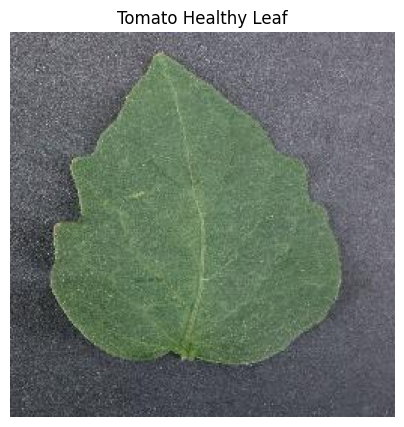

In [ ]:
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    sample_path = next(
        name for name in zip_ref.namelist()
        if "Tomato___healthy/" in name
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    )
    sample_bytes = zip_ref.read(sample_path)

sample_image = Image.open(BytesIO(sample_bytes)).convert("RGB")
print("Sample image path:", sample_path)
print("Sample image size:", sample_image.size)

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title("Tomato Healthy Leaf")
plt.axis("off")
plt.show()

## 3. Extract tomato images and inspect class distribution

In [ ]:
os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    tomato_files = [
        name for name in zip_ref.namelist()
        if name.startswith("plantvillage dataset/color/Tomato___")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Total tomato images to extract:", len(tomato_files))

    for file_name in tqdm(tomato_files, desc="Extracting tomato images"):
        relative_path = file_name.split("plantvillage dataset/color/", 1)[1]
        destination = os.path.join(dataset_path, relative_path)
        os.makedirs(os.path.dirname(destination), exist_ok=True)

        if not os.path.exists(destination):
            with zip_ref.open(file_name) as source, open(destination, "wb") as target:
                target.write(source.read())

total_images = sum(len(files) for _, _, files in os.walk(dataset_path))
print("Extraction complete.")
print("Total extracted files:", total_images)
print("Dataset location:", dataset_path)

Total Tomato images: 18160


Extracting:   0%|          | 0/18160 [00:00<?, ?it/s]

Extraction complete!


In [ ]:
classes = sorted(
    folder for folder in os.listdir(dataset_path)
    if folder.startswith("Tomato___")
    and os.path.isdir(os.path.join(dataset_path, folder))
)

print("Total classes:", len(classes))
for class_name in classes:
    class_folder = os.path.join(dataset_path, class_name)
    image_files = [
        name for name in os.listdir(class_folder)
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print(f"{class_name}: {len(image_files)} images")

Total classes: 10
Tomato___Bacterial_spot: 2127 images
Tomato___Early_blight: 1000 images
Tomato___Late_blight: 1909 images
Tomato___Leaf_Mold: 952 images
Tomato___Septoria_leaf_spot: 1771 images
Tomato___Spider_mites Two-spotted_spider_mite: 1676 images
Tomato___Target_Spot: 1404 images
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357 images
Tomato___Tomato_mosaic_virus: 373 images
Tomato___healthy: 1591 images


## 4. Create stratified training, validation, and test splits

In [ ]:
image_paths = []
labels = []

for class_name in classes:
    class_folder = os.path.join(dataset_path, class_name)
    for image_name in os.listdir(class_folder):
        if image_name.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_folder, image_name))
            labels.append(class_name)

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:", len(image_paths))

Training images: 12712
Validation images: 2724
Testing images: 2724
Total images: 18160


## 5. Image transformations, Dataset, and DataLoaders

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training and evaluation transformations are ready.")

Training transformations ready!
Validation and testing transformations ready!


In [ ]:
class TomatoDataset(Dataset):
    def __init__(self, image_paths, labels, classes, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.classes = classes
        self.transform = transform
        self.class_to_idx = {
            class_name: index
            for index, class_name in enumerate(classes)
        }

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        label_name = self.labels[index]

        image = Image.open(image_path).convert("RGB")
        label = self.class_to_idx[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label

print("TomatoDataset class created.")

TomatoDataset class created successfully!


In [ ]:
train_dataset = TomatoDataset(X_train, y_train, classes, transform=train_transform)
val_dataset = TomatoDataset(X_val, y_val, classes, transform=val_test_transform)
test_dataset = TomatoDataset(X_test, y_test, classes, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

images, batch_labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", batch_labels.shape)

Training batches: 398
Validation batches: 86
Testing batches: 86


## 6. Build the ResNet18 transfer-learning model

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(classes))
model = model.to(device)

# Freeze the pretrained backbone and train only the final classification layer.
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

print("Output classes:", len(classes))
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 7. Training and validation functions

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    return epoch_loss, epoch_accuracy


def evaluate_model(model, data_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = running_loss / len(data_loader)
    epoch_accuracy = 100 * correct / total
    return epoch_loss, epoch_accuracy


print("Training and evaluation functions are ready.")

Training function created successfully!


## 8. Train the model

In [ ]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

num_epochs = 5

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_acc = evaluate_model(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(f"\nEpoch [{epoch + 1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}%")


Epoch [1/5]
Train Loss: 0.8933 | Train Accuracy: 74.26%
Val Loss: 0.5022 | Val Accuracy: 86.67%

Epoch [2/5]
Train Loss: 0.4495 | Train Accuracy: 87.07%
Val Loss: 0.4183 | Val Accuracy: 86.86%

Epoch [3/5]
Train Loss: 0.3773 | Train Accuracy: 88.52%
Val Loss: 0.3414 | Val Accuracy: 89.21%

Epoch [4/5]
Train Loss: 0.3383 | Train Accuracy: 89.33%
Val Loss: 0.3147 | Val Accuracy: 89.46%

Epoch [5/5]
Train Loss: 0.3130 | Train Accuracy: 89.97%
Val Loss: 0.2980 | Val Accuracy: 90.46%


## 9. Evaluate on the held-out test set

In [ ]:
test_loss, test_accuracy = evaluate_model(
    model, test_loader, criterion, device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    digits=4
))

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9306    0.9248    0.9277       319
                        Tomato___Early_blight     0.8217    0.7067    0.7599       150
                         Tomato___Late_blight     0.9314    0.9021    0.9165       286
                           Tomato___Leaf_Mold     0.8378    0.8671    0.8522       143
                  Tomato___Septoria_leaf_spot     0.8561    0.9208    0.8873       265
Tomato___Spider_mites Two-spotted_spider_mite     0.8662    0.9246    0.8944       252
                         Tomato___Target_Spot     0.8750    0.8294    0.8516       211
       Tomato___Tomato_Yellow_Leaf_Curl_Virus     0.9669    0.9801    0.9734       804
                 Tomato___Tomato_mosaic_virus     0.8596    0.8750    0.8673        56
                             Tomato___healthy     0.9912    0.9454    0.9677       238

                                     accu

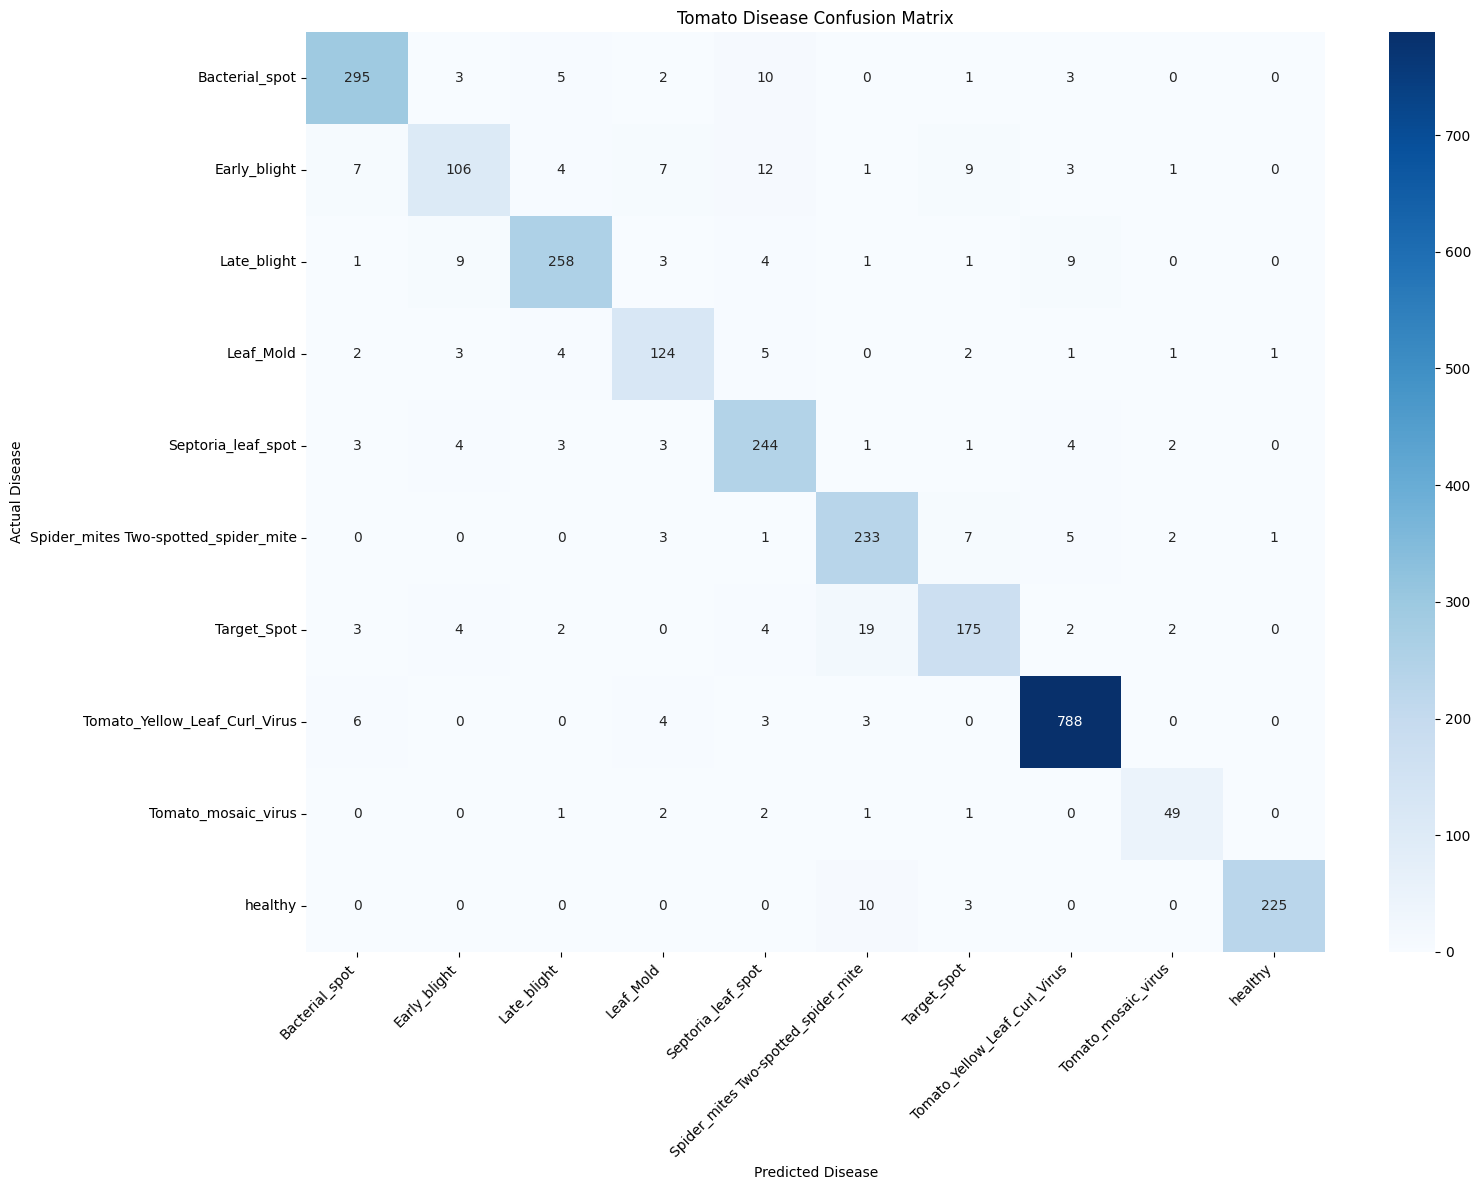

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)

display_classes = [name.replace("Tomato___", "") for name in classes]

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=display_classes,
    yticklabels=display_classes
)
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.title("Tomato Disease Classification - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

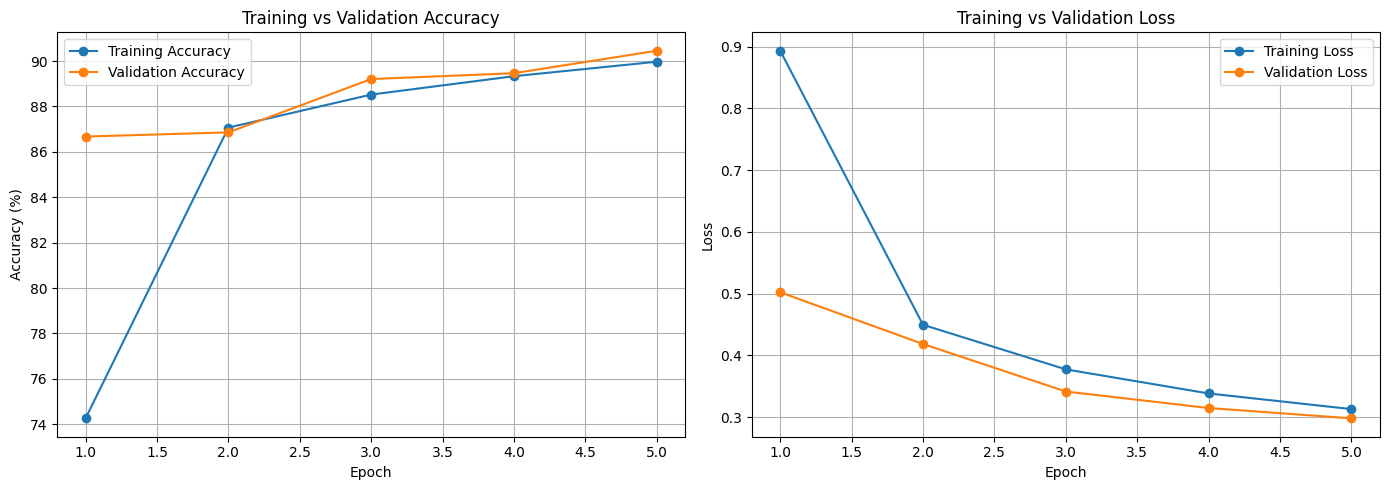

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 10. Save model, checkpoint, and evaluation metadata

In [ ]:
# Save the trained model weights.
model_weights_path = os.path.join(model_save_path, "tomato_resnet18.pth")
torch.save(model.state_dict(), model_weights_path)

# Save a checkpoint. This is the final epoch checkpoint, not a validation-selected best checkpoint.
checkpoint = {
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "num_classes": len(classes),
    "model_name": "ResNet18",
    "test_accuracy": test_accuracy,
    "epochs": num_epochs
}

checkpoint_path = os.path.join(model_save_path, "final_model_checkpoint.pth")
torch.save(checkpoint, checkpoint_path)

# Save training history, class mapping, and test results.
with open(os.path.join(results_save_path, "training_history.json"), "w") as file:
    json.dump(history, file, indent=4)

class_mapping = {index: class_name for index, class_name in enumerate(classes)}
with open(os.path.join(results_save_path, "class_mapping.json"), "w") as file:
    json.dump(class_mapping, file, indent=4)

results = {
    "model": "ResNet18",
    "dataset": "PlantVillage Tomato",
    "num_classes": len(classes),
    "test_accuracy": round(test_accuracy, 2),
    "test_loss": round(test_loss, 4),
    "epochs": num_epochs
}
with open(os.path.join(results_save_path, "model_results.json"), "w") as file:
    json.dump(results, file, indent=4)

print("Model and results saved successfully.")
print("Model folder:", model_save_path)
print("Results folder:", results_save_path)
print(results)

Best model checkpoint saved successfully!


## 11. Test predictions on individual images

In [ ]:
def predict_image(image_path, model, classes, transform, device):
    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_class = probabilities.max(dim=1)

    predicted_disease = classes[predicted_class.item()]
    confidence_score = confidence.item() * 100
    return predicted_disease, confidence_score


# Test one image from the held-out test set.
image_path = X_test[0]
predicted_disease, confidence = predict_image(
    image_path, model, classes, val_test_transform, device
)

actual_disease = y_test[0]
print("Actual Disease:", actual_disease)
print("Predicted Disease:", predicted_disease)
print(f"Confidence: {confidence:.2f}%")

image = Image.open(image_path).convert("RGB")
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(f"Prediction: {predicted_disease}\nConfidence: {confidence:.2f}%")
plt.axis("off")
plt.show()

Image Path: /content/tomato_dataset/Tomato___Target_Spot/7e17c9eb-b1ed-4e52-8fe2-02f73d93ed3a___Com.G_TgS_FL 8221.JPG
Predicted Disease: Tomato___Target_Spot
Confidence: 98.10%


In [ ]:
# Inspect predictions on 10 randomly selected test images.
random_indices = random.sample(range(len(X_test)), 10)

for index in random_indices:
    image_path = X_test[index]
    actual_label = y_test[index]
    predicted_name, confidence = predict_image(
        image_path, model, classes, val_test_transform, device
    )

    print("Actual:", actual_label)
    print("Predicted:", predicted_name)
    print(f"Confidence: {confidence:.2f}%")
    print("Correct:", actual_label == predicted_name)
    print("-" * 60)

Actual: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 85.92%
Correct: True
------------------------------------------------------------
Actual: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 96.85%
Correct: True
------------------------------------------------------------
Actual: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 99.34%
Correct: True
------------------------------------------------------------
Actual: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 99.67%
Correct: True
------------------------------------------------------------
Actual: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 95.91%
Correct: True
------------------------------------------------------------
Actual: Tomato___Late_blight
Predicted: Tomat

## 12. Verify the saved checkpoint

In [ ]:
loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Model Name:", loaded_checkpoint["model_name"])
print("Number of Classes:", loaded_checkpoint["num_classes"])
print("Test Accuracy:", loaded_checkpoint["test_accuracy"])
print("Training Epochs:", loaded_checkpoint["epochs"])
print("Checkpoint loaded successfully.")

Model Name: ResNet18
Number of Classes: 10
Test Accuracy: 91.66666666666667
Training Epochs: 5
Checkpoint loaded successfully!


## 13. Notes and limitations

- The reported test accuracy is measured on the held-out PlantVillage tomato test split.
- PlantVillage images are relatively controlled. Real field images may contain different lighting, backgrounds, camera quality, and multiple symptoms.
- The model has not yet been validated on independent real-world farm images.
- The model uses a frozen ResNet18 backbone and trains only the final classification layer for five epochs.
- The checkpoint saved here is the final epoch checkpoint. It is not selected by a separate best-validation-checkpoint mechanism.